# LAB 3 – Bài 2 (Trang 18 – 19): Gom cụm khách hàng Mall Customers bằng k-Means

In [1]:
HO_TEN = "Trang Kim Đạt"
MSSV = "6451071018"
print(f"{HO_TEN} – {MSSV}")

Trang Kim Đạt – 6451071018


In [2]:
print(f"{HO_TEN} – {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

Trang Kim Đạt – 6451071018


## Câu 1) Nhập dữ liệu, thống kê thông tin cơ bản, xử lý dữ liệu thiếu

In [3]:
print(f"{HO_TEN} – {MSSV}")
df = pd.read_csv("Mall_Customers.csv")
print("Kích thước:", df.shape)
df.head()

Trang Kim Đạt – 6451071018
Kích thước: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
print(f"{HO_TEN} – {MSSV}")
df.info()

Trang Kim Đạt – 6451071018
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
print(f"{HO_TEN} – {MSSV}")
df.describe(include='all')

Trang Kim Đạt – 6451071018


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [6]:
print(f"{HO_TEN} – {MSSV}")
print("Số giá trị thiếu theo từng cột:")
print(df.isnull().sum())

Trang Kim Đạt – 6451071018
Số giá trị thiếu theo từng cột:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
print(f"{HO_TEN} – {MSSV}")
# Xử lý dữ liệu thiếu: thuộc tính số -> điền trung vị; thuộc tính phân loại -> điền giá trị phổ biến nhất
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == "object":
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())
print("Sau xử lý, tổng số giá trị thiếu:", int(df.isnull().sum().sum()))

Trang Kim Đạt – 6451071018
Sau xử lý, tổng số giá trị thiếu: 0


## Câu 2) Histogram phân phối Tuổi, Thu nhập hằng năm, Số điểm mua sắm

Trang Kim Đạt – 6451071018


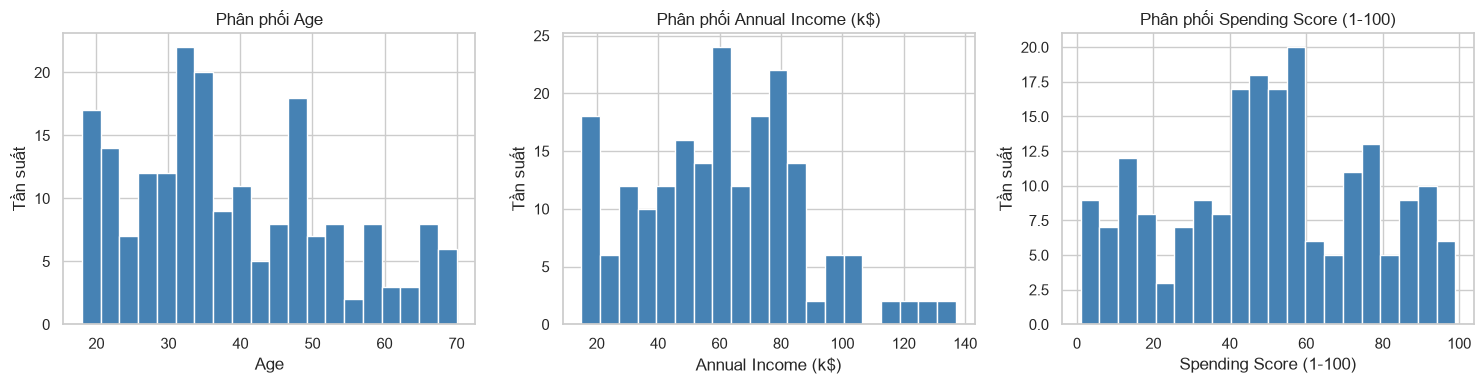

In [8]:
print(f"{HO_TEN} – {MSSV}")
cot_so = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cot_so):
    ax.hist(df[col], bins=20, color="steelblue", edgecolor="white")
    ax.set_title(f"Phân phối {col}")
    ax.set_xlabel(col); ax.set_ylabel("Tần suất")
plt.tight_layout(); plt.show()

## Câu 3) Thống kê số mẫu theo Giới tính

Trang Kim Đạt – 6451071018
Gender
Female    112
Male       88
Name: count, dtype: int64


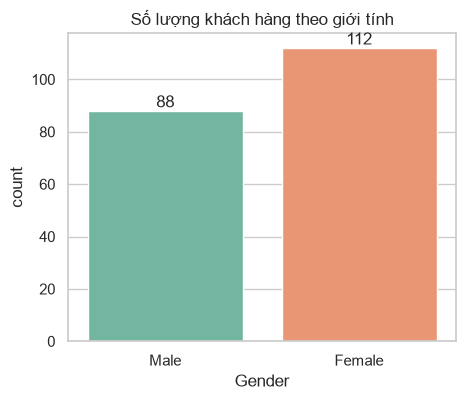

In [9]:
print(f"{HO_TEN} – {MSSV}")
dem_gioi_tinh = df["Gender"].value_counts()
print(dem_gioi_tinh)
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Gender", hue="Gender", palette="Set2", legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Số lượng khách hàng theo giới tính")
plt.show()

## Câu 4) Scatter plot: Tuổi và Thu nhập hằng năm theo Giới tính

Trang Kim Đạt – 6451071018


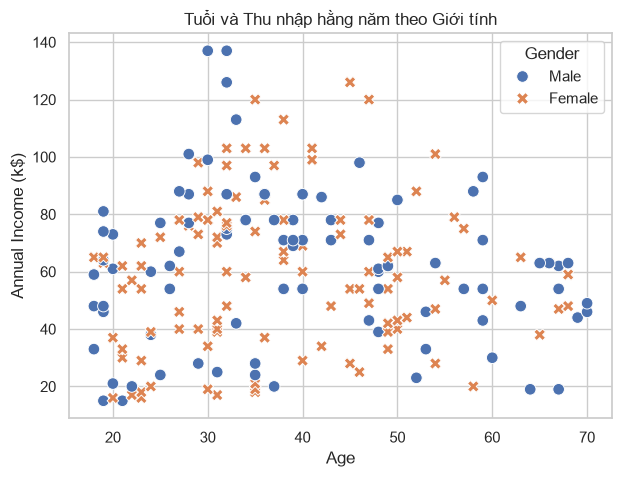

In [10]:
print(f"{HO_TEN} – {MSSV}")
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Age", y="Annual Income (k$)", hue="Gender", style="Gender", s=70)
plt.title("Tuổi và Thu nhập hằng năm theo Giới tính")
plt.show()

## Câu 5) Scatter plot: Thu nhập hằng năm và Số điểm mua sắm theo Giới tính

Trang Kim Đạt – 6451071018


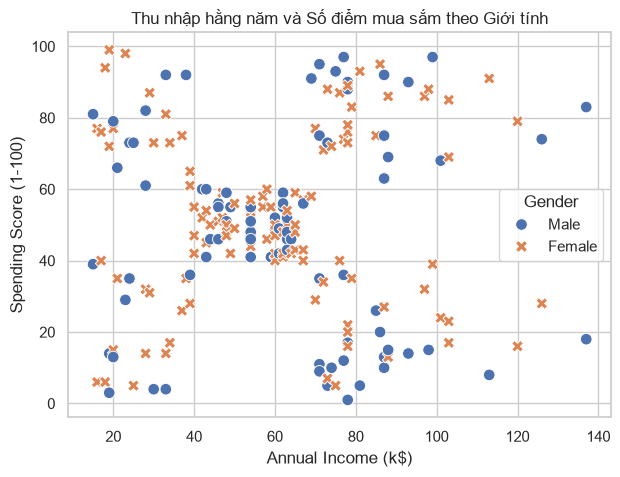

In [11]:
print(f"{HO_TEN} – {MSSV}")
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Gender", style="Gender", s=70)
plt.title("Thu nhập hằng năm và Số điểm mua sắm theo Giới tính")
plt.show()

## Câu 6, 7, 8) Gom cụm theo **Tuổi** và **Số điểm mua sắm**
Các bước: (6) Elbow method xác định k → k-Means; (7) biểu diễn kết quả; (8) đánh giá bằng Silhouette coefficient.

Hàm tiện ích bên dưới dùng chung cho cả 3 trường hợp (câu 6–8 và câu 9). Số cụm k được chọn **bằng mắt** tại vị trí khuỷu tay của đường cong WSS (điểm mà thêm cụm không làm WSS giảm đáng kể). Để có thêm căn cứ, notebook in kèm gợi ý tự động (khoảng cách xa nhất đến đường nối hai đầu mút của đường cong) và Silhouette theo từng k.

In [12]:
print(f"{HO_TEN} – {MSSV}")
def tinh_wss(X, k_max=10):
    """WSS (Inertia) ứng với k = 1..k_max."""
    return [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, k_max + 1)]

def chon_k_elbow(wss):
    """Chọn k tại vị trí khuỷu tay: điểm xa nhất so với đường thẳng nối đầu - cuối của đường cong WSS."""
    k = np.arange(1, len(wss) + 1, dtype=float)
    w = np.array(wss, dtype=float)
    kn = (k - k.min()) / (k.max() - k.min())
    wn = (w - w.min()) / (w.max() - w.min())
    khoang_cach = np.abs(kn + wn - 1) / np.sqrt(2)
    return int(np.argmax(khoang_cach)) + 1

def silhouette_theo_k(X, k_max=10):
    return {k: round(silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)), 3) for k in range(2, k_max + 1)}

def ve_elbow(wss, k_chon, tieu_de):
    print("Gợi ý k theo khoảng cách tới đường nối hai đầu:", chon_k_elbow(wss))
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(wss) + 1), wss, "o-")
    plt.axvline(k_chon, color="red", linestyle="--", label=f"k = {k_chon}")
    plt.title(f"Elbow method - {tieu_de}")
    plt.xlabel("Số cụm k"); plt.ylabel("WSS (Inertia)"); plt.legend()
    plt.show()

Trang Kim Đạt – 6451071018


Trang Kim Đạt – 6451071018
Gợi ý k theo khoảng cách tới đường nối hai đầu: 3


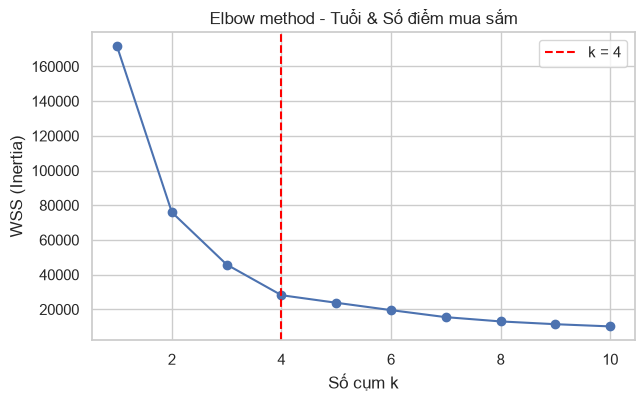

Số cụm chọn theo Elbow: k = 4
Silhouette theo k: {2: 0.469, 3: 0.453, 4: 0.5, 5: 0.445, 6: 0.448, 7: 0.423, 8: 0.428, 9: 0.414, 10: 0.407}


In [13]:
print(f"{HO_TEN} – {MSSV}")
cot_1 = ["Age", "Spending Score (1-100)"]
X1 = df[cot_1].values
wss1 = tinh_wss(X1)
k1 = 4   # chọn tại khuỷu tay của đường cong WSS
ve_elbow(wss1, k1, "Tuổi & Số điểm mua sắm")
print("Số cụm chọn theo Elbow: k =", k1)
print("Silhouette theo k:", silhouette_theo_k(X1))

In [14]:
print(f"{HO_TEN} – {MSSV}")
kmeans1 = KMeans(n_clusters=k1, n_init=10, random_state=42).fit(X1)
df["Cluster_Age_Spending"] = kmeans1.labels_
print("Số mẫu mỗi cụm:"); print(df["Cluster_Age_Spending"].value_counts().sort_index())

Trang Kim Đạt – 6451071018
Số mẫu mỗi cụm:
Cluster_Age_Spending
0    48
1    57
2    48
3    47
Name: count, dtype: int64


Trang Kim Đạt – 6451071018


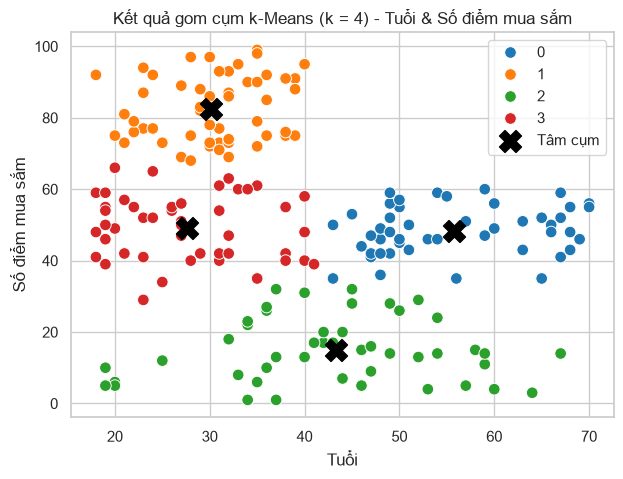

In [15]:
print(f"{HO_TEN} – {MSSV}")
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X1[:, 0], y=X1[:, 1], hue=kmeans1.labels_, palette="tab10", s=70)
plt.scatter(kmeans1.cluster_centers_[:, 0], kmeans1.cluster_centers_[:, 1], c="black", marker="X", s=250, label="Tâm cụm")
plt.xlabel("Tuổi"); plt.ylabel("Số điểm mua sắm"); plt.title(f"Kết quả gom cụm k-Means (k = {k1}) - Tuổi & Số điểm mua sắm")
plt.legend(); plt.show()

In [16]:
print(f"{HO_TEN} – {MSSV}")
sil1 = silhouette_score(X1, kmeans1.labels_)
print(f"Silhouette coefficient (Tuổi & Số điểm mua sắm, k = {k1}): {sil1:.4f}")

Trang Kim Đạt – 6451071018
Silhouette coefficient (Tuổi & Số điểm mua sắm, k = 4): 0.4997


## Câu 9a) Gom cụm theo **Thu nhập hằng năm** và **Số điểm mua sắm**

Trang Kim Đạt – 6451071018
Gợi ý k theo khoảng cách tới đường nối hai đầu: 5


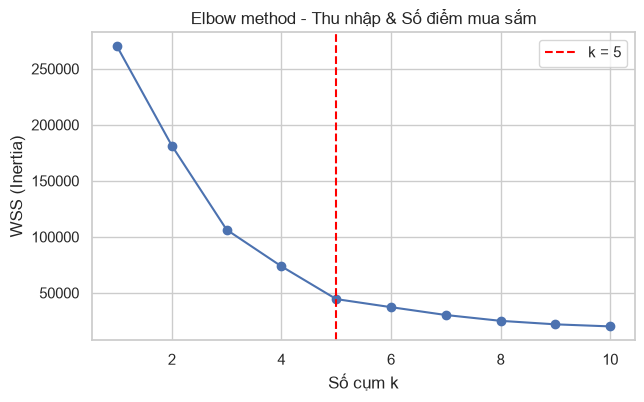

Số cụm chọn theo Elbow: k = 5
Silhouette theo k: {2: 0.297, 3: 0.468, 4: 0.493, 5: 0.554, 6: 0.54, 7: 0.529, 8: 0.455, 9: 0.456, 10: 0.441}
Số mẫu mỗi cụm:
Cluster_Income_Spending
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [17]:
print(f"{HO_TEN} – {MSSV}")
cot_2 = ["Annual Income (k$)", "Spending Score (1-100)"]
X2 = df[cot_2].values
wss2 = tinh_wss(X2)
k2 = 5   # chọn tại khuỷu tay của đường cong WSS
ve_elbow(wss2, k2, "Thu nhập & Số điểm mua sắm")
print("Số cụm chọn theo Elbow: k =", k2)
print("Silhouette theo k:", silhouette_theo_k(X2))

kmeans2 = KMeans(n_clusters=k2, n_init=10, random_state=42).fit(X2)
df["Cluster_Income_Spending"] = kmeans2.labels_
print("Số mẫu mỗi cụm:"); print(df["Cluster_Income_Spending"].value_counts().sort_index())

Trang Kim Đạt – 6451071018


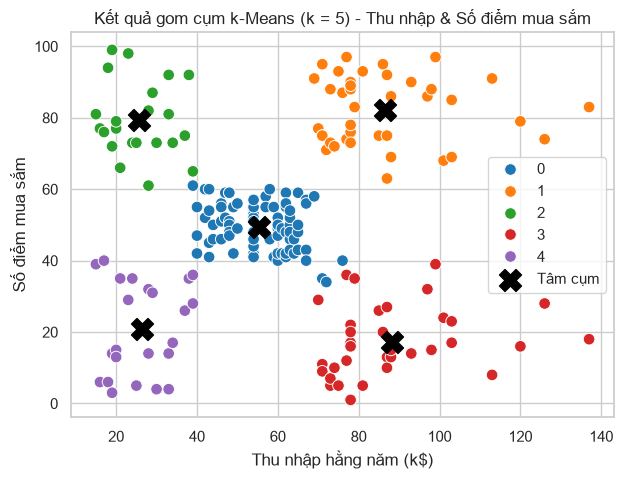

Silhouette coefficient (Thu nhập & Số điểm mua sắm, k = 5): 0.5539


In [18]:
print(f"{HO_TEN} – {MSSV}")
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=kmeans2.labels_, palette="tab10", s=70)
plt.scatter(kmeans2.cluster_centers_[:, 0], kmeans2.cluster_centers_[:, 1], c="black", marker="X", s=250, label="Tâm cụm")
plt.xlabel("Thu nhập hằng năm (k$)"); plt.ylabel("Số điểm mua sắm")
plt.title(f"Kết quả gom cụm k-Means (k = {k2}) - Thu nhập & Số điểm mua sắm")
plt.legend(); plt.show()

sil2 = silhouette_score(X2, kmeans2.labels_)
print(f"Silhouette coefficient (Thu nhập & Số điểm mua sắm, k = {k2}): {sil2:.4f}")

## Câu 9b) Gom cụm theo **Tuổi**, **Thu nhập hằng năm** và **Số điểm mua sắm** (biểu đồ 3D)

Trang Kim Đạt – 6451071018
Gợi ý k theo khoảng cách tới đường nối hai đầu: 4


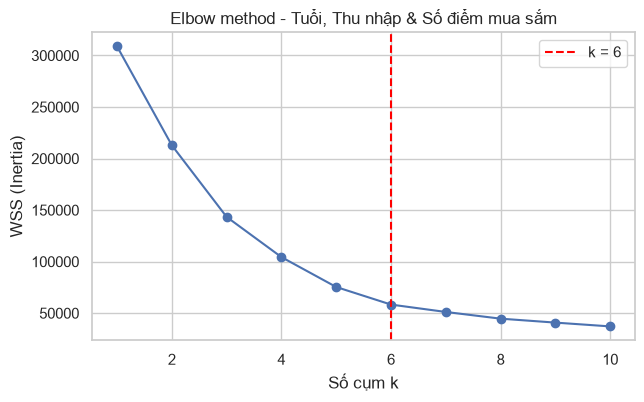

Số cụm chọn theo Elbow: k = 6
Silhouette theo k: {2: 0.293, 3: 0.384, 4: 0.405, 5: 0.444, 6: 0.452, 7: 0.439, 8: 0.433, 9: 0.398, 10: 0.382}
Số mẫu mỗi cụm:
Cluster_3D
0    45
1    35
2    22
3    38
4    39
5    21
Name: count, dtype: int64
Silhouette coefficient (3 thuộc tính, k = 6): 0.4523


In [19]:
print(f"{HO_TEN} – {MSSV}")
cot_3 = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X3 = df[cot_3].values
wss3 = tinh_wss(X3)
k3 = 6   # chọn tại khuỷu tay của đường cong WSS
ve_elbow(wss3, k3, "Tuổi, Thu nhập & Số điểm mua sắm")
print("Số cụm chọn theo Elbow: k =", k3)
print("Silhouette theo k:", silhouette_theo_k(X3))

kmeans3 = KMeans(n_clusters=k3, n_init=10, random_state=42).fit(X3)
df["Cluster_3D"] = kmeans3.labels_
print("Số mẫu mỗi cụm:"); print(df["Cluster_3D"].value_counts().sort_index())
sil3 = silhouette_score(X3, kmeans3.labels_)
print(f"Silhouette coefficient (3 thuộc tính, k = {k3}): {sil3:.4f}")

In [20]:
print(f"{HO_TEN} – {MSSV}")
# Biểu đồ 3D tương tác bằng plotly
fig = px.scatter_3d(df, x="Age", y="Annual Income (k$)", z="Spending Score (1-100)",
                    color=df["Cluster_3D"].astype(str), opacity=0.85,
                    title=f"Kết quả gom cụm k-Means 3D (k = {k3})", labels={"color": "Cụm"})
fig.update_traces(marker=dict(size=4))
fig.update_layout(width=800, height=650)
fig.show()

Trang Kim Đạt – 6451071018


Trang Kim Đạt – 6451071018


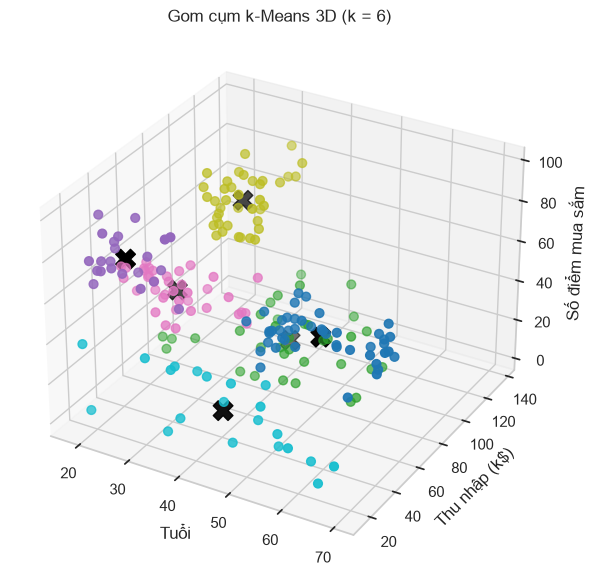

In [21]:
print(f"{HO_TEN} – {MSSV}")
# Biểu đồ 3D tĩnh bằng matplotlib (để vẫn xem được khi môi trường không hiển thị plotly)
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=kmeans3.labels_, cmap="tab10", s=40)
ax.scatter(*kmeans3.cluster_centers_.T, c="black", marker="X", s=200)
ax.set_xlabel("Tuổi"); ax.set_ylabel("Thu nhập (k$)"); ax.set_zlabel("Số điểm mua sắm")
ax.set_title(f"Gom cụm k-Means 3D (k = {k3})")
plt.show()

### Tổng hợp Silhouette coefficient của 3 trường hợp

In [22]:
print(f"{HO_TEN} – {MSSV}")
pd.DataFrame({
    "Thuộc tính gom cụm": ["Tuổi & Số điểm mua sắm", "Thu nhập & Số điểm mua sắm", "Tuổi, Thu nhập & Số điểm mua sắm"],
    "k (Elbow)": [k1, k2, k3],
    "Silhouette": [sil1, sil2, sil3],
}).round(4)

Trang Kim Đạt – 6451071018


,Thuộc tính gom cụm,k (Elbow),Silhouette
0,Tuổi & Số điểm mua sắm,4,0.4997
1,Thu nhập & Số điểm mua sắm,5,0.5539
2,"Tuổi, Thu nhập & Số điểm mua sắm",6,0.4523
